## Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
% matplotlib inline

sns.set_style("darkgrid")
sns.set_context("paper")

import warnings
warnings.filterwarnings('ignore')

# Resolve paths when the notebook starts in Code/ or the repository root.
repo_dir = Path(".") if Path("Data").is_dir() else Path("..")
data_dir = repo_dir / "Data"
figure_dir = repo_dir / "figures" / "box_plot"
figure_dir.mkdir(parents=True, exist_ok=True)


UsageError: Line magic function `%` not found.


## Load input data

In [4]:
income = pd.read_csv(data_dir / "socioeconomic variables/median household income.csv")
House_value = pd.read_csv(data_dir / "socioeconomic variables/median house value.csv")
minority = pd.read_csv(data_dir / "socioeconomic variables/% non-hispanic and non-black.csv")
Vehicle = pd.read_csv(data_dir / "socioeconomic variables/% households having vehicles.csv")
hdt = pd.read_csv(data_dir / "home dwelling time/Timedwelling_mean_value_non_3.csv")
ntl = pd.read_csv(data_dir / "nighttime light data/ntl.csv")

In [5]:
ntl_216 = pd.read_csv(data_dir / "nighttime light data/ntl_0216.csv")

In [7]:
ntl_207 = pd.read_csv(data_dir / "nighttime light data/ntl_0207.csv")
ntl_207.head()

,GEOID,value,date
0,48201100000,2742.191496,2021-02-07
1,48201210400,599.307341,2021-02-07
2,48201210500,681.452535,2021-02-07
3,48201210600,569.385663,2021-02-07
4,48201210700,434.074465,2021-02-07


## Descriptive checks for home-dwelling time

In [10]:
hdt['mean_13_14'].describe()

count    781.000000
mean      11.338093
std       17.302098
min      -77.654176
25%        4.063583
50%        8.980035
75%       15.362901
max      223.333333
Name: mean_13_14, dtype: float64

In [11]:
len(hdt[(hdt['mean_13_14'] <= 40) & (hdt['mean_13_14'] > 30)])

26

In [12]:
len(hdt[(hdt['mean_13_14'] > 40)])

37

In [14]:
hdt['mean_19_28'].describe()

count    781.000000
mean       3.040753
std       12.993862
min      -51.255484
25%       -2.647412
50%        1.518904
75%        6.280034
max       99.283382
Name: mean_19_28, dtype: float64

In [15]:
len(hdt[(hdt['mean_19_28'] > 40)])

11

In [16]:
len(hdt[(hdt['mean_19_28'] <= 40) & (hdt['mean_19_28'] > 30)])

14

## Group comparisons and pairwise heatmaps

### Median household income

In [23]:
merge_income1 = pd.merge(income, hdt, left_on='GEOID', right_on='census_tract', how='left')
merge_income2 = pd.merge(merge_income1, ntl, left_on='GEOID', right_on='GEOID', how='left')
merge_income2['ntl1'] = (-merge_income2['ntl']) * 100
merge_income2.head()

,GEOID,income_rank,catogroy,census_tract,mean_13_14,mean_15_18,mean_19_28,ntl,ntl1
0,48201100000,0.784891,Q4,48201100000,23.249437,21.757653,-12.321885,-0.251687,25.168702
1,48201210400,0.180538,Q1,48201210400,38.512239,20.350594,5.827102,0.219782,-21.978191
2,48201210500,0.199744,Q1,48201210500,9.819623,43.643126,4.142784,-0.098852,9.885152
3,48201210600,0.518566,Q3,48201210600,7.412045,12.924301,18.390544,-0.578316,57.831642
4,48201210700,0.234315,Q2,48201210700,28.489654,37.531816,-4.864677,0.637659,-63.765865


In [24]:
merge_income_nlt_1 = pd.merge(income, ntl_207, left_on='GEOID', right_on='GEOID', how='left')
merge_income_nlt_2 = pd.merge(merge_income_nlt_1, ntl_216, left_on='GEOID', right_on='GEOID', how='left')
merge_income_nlt_2.head()

,GEOID,income_rank,catogroy,value_x,date_x,value_y,date_y
0,48201100000,0.784891,Q4,2742.191496,2021-02-07,2052.017486,2021-02-16
1,48201210400,0.180538,Q1,599.307341,2021-02-07,731.024252,2021-02-16
2,48201210500,0.199744,Q1,681.452535,2021-02-07,614.089915,2021-02-16
3,48201210600,0.518566,Q3,569.385663,2021-02-07,240.100587,2021-02-16
4,48201210700,0.234315,Q2,434.074465,2021-02-07,710.865803,2021-02-16


In [25]:
merge_income_nlt_2['nlt'] = (merge_income_nlt_2['value_x'] - merge_income_nlt_2['value_y']) / merge_income_nlt_2['value_x']
merge_income_nlt_2.head()

,GEOID,income_rank,catogroy,value_x,date_x,value_y,date_y,nlt
0,48201100000,0.784891,Q4,2742.191496,2021-02-07,2052.017486,2021-02-16,0.251687
1,48201210400,0.180538,Q1,599.307341,2021-02-07,731.024252,2021-02-16,-0.219782
2,48201210500,0.199744,Q1,681.452535,2021-02-07,614.089915,2021-02-16,0.098852
3,48201210600,0.518566,Q3,569.385663,2021-02-07,240.100587,2021-02-16,0.578316
4,48201210700,0.234315,Q2,434.074465,2021-02-07,710.865803,2021-02-16,-0.637659


In [118]:
import scipy.stats as stats
print(stats.kruskal(merge_income2[merge_income2['catogroy']=='Q1']['mean_13_14'], merge_income2[merge_income2['catogroy']=='Q2']['mean_13_14'], merge_income2[merge_income2['catogroy']=='Q3']['mean_13_14'], merge_income2[merge_income2['catogroy']=='Q4']['mean_13_14'], merge_income2[merge_income2['catogroy']=='Q5']['mean_13_14']))
print(stats.kruskal(merge_income2[merge_income2['catogroy']=='Q1']['ntl1'], merge_income2[merge_income2['catogroy']=='Q2']['ntl1'], merge_income2[merge_income2['catogroy']=='Q3']['ntl1'], merge_income2[merge_income2['catogroy']=='Q4']['ntl1'], merge_income2[merge_income2['catogroy']=='Q5']['ntl1']))
print(stats.kruskal(merge_income2[merge_income2['catogroy']=='Q1']['mean_19_28'], merge_income2[merge_income2['catogroy']=='Q2']['mean_19_28'], merge_income2[merge_income2['catogroy']=='Q3']['mean_19_28'], merge_income2[merge_income2['catogroy']=='Q4']['mean_19_28'], merge_income2[merge_income2['catogroy']=='Q5']['mean_19_28']))

KruskalResult(statistic=14.321851995772704, pvalue=0.0063356152216800885)
KruskalResult(statistic=9.836494908240184, pvalue=0.04327383551624482)
KruskalResult(statistic=6.437579500548054, pvalue=0.16876611586073176)


#### Dunn test for the initial-hit stage

In [ ]:
import scikit_posthocs as sp

In [30]:
sp.posthoc_dunn([merge_income2[merge_income2['catogroy']=="Q1"]['mean_13_14'], merge_income2[merge_income2['catogroy']=="Q2"]['mean_13_14']], p_adjust = 'bonferroni')[1][2]

0.13692327356138762

In [31]:
group1 = merge_income2[merge_income2['catogroy']=="Q1"]['mean_13_14']
group2 = merge_income2[merge_income2['catogroy']=="Q2"]['mean_13_14']
group3 = merge_income2[merge_income2['catogroy']=="Q3"]['mean_13_14']
group4 = merge_income2[merge_income2['catogroy']=="Q4"]['mean_13_14']
group5 = merge_income2[merge_income2['catogroy']=="Q5"]['mean_13_14']
data = [group1,group2,group3,group4,group5]

In [33]:
test_df = sp.posthoc_dunn(data, p_adjust = 'bonferroni')
test_df

,1,2,3,4,5
1,1.000000,1.000000,0.029444,0.009139,0.096749
2,1.000000,1.000000,1.000000,0.817576,1.000000
3,0.029444,1.000000,1.000000,1.000000,1.000000
4,0.009139,0.817576,1.000000,1.000000,1.000000
5,0.096749,1.000000,1.000000,1.000000,1.000000


In [35]:
test_df_new = test_df.rename(columns={1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4', 5: 'Q5'}, index={1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4', 5: 'Q5'})

In [36]:
test_df_new

,Q1,Q2,Q3,Q4,Q5
Q1,1.000000,1.000000,0.029444,0.009139,0.096749
Q2,1.000000,1.000000,1.000000,0.817576,1.000000
Q3,0.029444,1.000000,1.000000,1.000000,1.000000
Q4,0.009139,0.817576,1.000000,1.000000,1.000000
Q5,0.096749,1.000000,1.000000,1.000000,1.000000


#### Income heatmaps

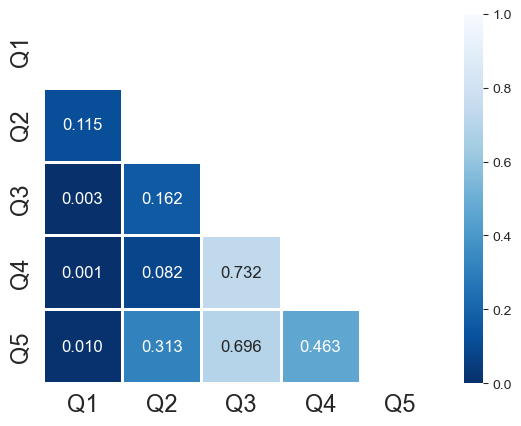

In [135]:
group1 = merge_income2[merge_income2['catogroy']=="Q1"]['mean_13_14']
group2 = merge_income2[merge_income2['catogroy']=="Q2"]['mean_13_14']
group3 = merge_income2[merge_income2['catogroy']=="Q3"]['mean_13_14']
group4 = merge_income2[merge_income2['catogroy']=="Q4"]['mean_13_14']
group5 = merge_income2[merge_income2['catogroy']=="Q5"]['mean_13_14']
data = [group1,group2,group3,group4,group5]

test_df = sp.posthoc_dunn(data)
table = test_df.rename(columns={1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4', 5: 'Q5'}, index={1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4', 5: 'Q5'})
mask = np.triu(np.ones_like(table))

dataplot = sns.heatmap(table, cmap='Blues_r', linewidths=1, annot=True, annot_kws={'size': 12}, fmt=".3f", mask=mask, vmin=0, vmax=1) #, , center=0.05, cbar=False
plt.xticks(fontsize=17,fontname = "Arial")
plt.yticks(fontsize=17,fontname = "Arial")
plt.savefig(figure_dir / "income_initialhit.png",dpi=300)
plt.show()

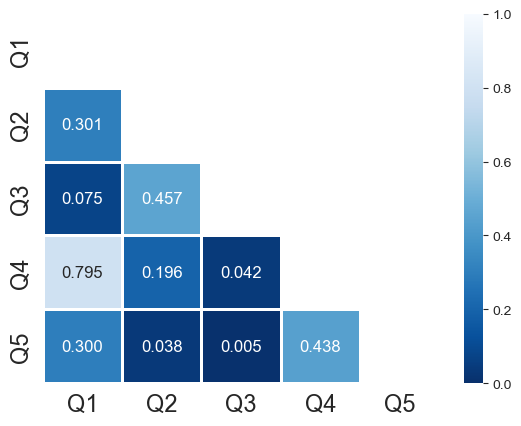

In [136]:
group1 = merge_income2[merge_income2['catogroy']=="Q1"]['ntl1']
group2 = merge_income2[merge_income2['catogroy']=="Q2"]['ntl1']
group3 = merge_income2[merge_income2['catogroy']=="Q3"]['ntl1']
group4 = merge_income2[merge_income2['catogroy']=="Q4"]['ntl1']
group5 = merge_income2[merge_income2['catogroy']=="Q5"]['ntl1']
data = [group1,group2,group3,group4,group5]

test_df = sp.posthoc_dunn(data)
table = test_df.rename(columns={1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4', 5: 'Q5'}, index={1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4', 5: 'Q5'})
mask = np.triu(np.ones_like(table))

dataplot = sns.heatmap(table, cmap='Blues_r', linewidths=1, annot=True, annot_kws={'size': 12}, fmt=".3f", mask=mask, vmin=0, vmax=1) #, , center=0.05, cbar=False
plt.xticks(fontsize=17,fontname = "Arial")
plt.yticks(fontsize=17,fontname = "Arial")
plt.savefig(figure_dir / "income_poweroutage.png",dpi=300)
plt.show()

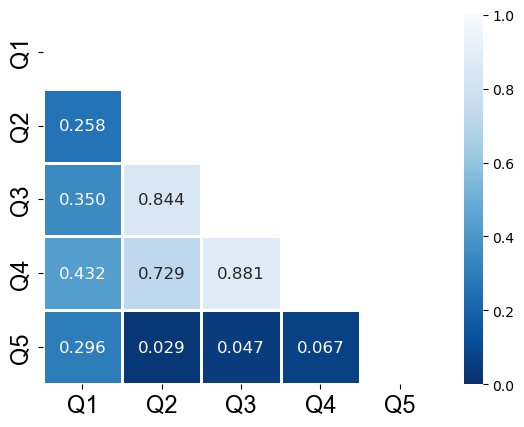

In [106]:
group1 = merge_income2[merge_income2['catogroy']=="Q1"]['mean_19_28']
group2 = merge_income2[merge_income2['catogroy']=="Q2"]['mean_19_28']
group3 = merge_income2[merge_income2['catogroy']=="Q3"]['mean_19_28']
group4 = merge_income2[merge_income2['catogroy']=="Q4"]['mean_19_28']
group5 = merge_income2[merge_income2['catogroy']=="Q5"]['mean_19_28']
data = [group1,group2,group3,group4,group5]

test_df = sp.posthoc_dunn(data)
table = test_df.rename(columns={1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4', 5: 'Q5'}, index={1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4', 5: 'Q5'})
mask = np.triu(np.ones_like(table))

dataplot = sns.heatmap(table, cmap='Blues_r', linewidths=1, annot=True, annot_kws={'size': 12}, fmt=".3f", mask=mask, vmin=0, vmax=1) #, , center=0.05, cbar=False
plt.xticks(fontsize=17,fontname = "Arial")
plt.yticks(fontsize=17,fontname = "Arial")
plt.savefig(figure_dir / "income_recovery.png",dpi=300)
plt.show()

### Median house value

In [84]:
merge_House_value1 = pd.merge(House_value, hdt, left_on='GEOID', right_on='census_tract', how='left')
merge_House_value2 = pd.merge(merge_House_value1, ntl, left_on='GEOID', right_on='GEOID', how='left')
merge_House_value2['ntl1'] = (-merge_House_value2['ntl']) * 100
merge_House_value2.head()

,GEOID,value_rank,catogroy,census_tract,mean_13_14,mean_15_18,mean_19_28,ntl,ntl1
0,48201100000,0.820743,Q5,48201100000,23.249437,21.757653,-12.321885,-0.251687,25.168702
1,48201210400,0.434059,Q3,48201210400,38.512239,20.350594,5.827102,0.219782,-21.978191
2,48201210500,0.558259,Q3,48201210500,9.819623,43.643126,4.142784,-0.098852,9.885152
3,48201210600,0.728553,Q4,48201210600,7.412045,12.924301,18.390544,-0.578316,57.831642
4,48201210700,0.366197,Q2,48201210700,28.489654,37.531816,-4.864677,0.637659,-63.765865


In [85]:
merge_House_value_nlt_207 = pd.merge(House_value, ntl_207, left_on='GEOID', right_on='GEOID', how='left')
merge_House_value_nlt_216 = pd.merge(House_value, ntl_216, left_on='GEOID', right_on='GEOID', how='left')

In [119]:
print(stats.kruskal(merge_House_value2[merge_House_value2['catogroy']=='Q1']['mean_13_14'], merge_House_value2[merge_House_value2['catogroy']=='Q2']['mean_13_14'], merge_House_value2[merge_House_value2['catogroy']=='Q3']['mean_13_14'], merge_House_value2[merge_House_value2['catogroy']=='Q4']['mean_13_14'], merge_House_value2[merge_House_value2['catogroy']=='Q5']['mean_13_14']))
print(stats.kruskal(merge_House_value2[merge_House_value2['catogroy']=='Q1']['ntl1'], merge_House_value2[merge_House_value2['catogroy']=='Q2']['ntl1'], merge_House_value2[merge_House_value2['catogroy']=='Q3']['ntl1'], merge_House_value2[merge_House_value2['catogroy']=='Q4']['ntl1'], merge_House_value2[merge_House_value2['catogroy']=='Q5']['ntl1']))
print(stats.kruskal(merge_House_value2[merge_House_value2['catogroy']=='Q1']['mean_19_28'], merge_House_value2[merge_House_value2['catogroy']=='Q2']['mean_19_28'], merge_House_value2[merge_House_value2['catogroy']=='Q3']['mean_19_28'], merge_House_value2[merge_House_value2['catogroy']=='Q4']['mean_19_28'], merge_House_value2[merge_House_value2['catogroy']=='Q5']['mean_19_28']))

KruskalResult(statistic=10.913695442221979, pvalue=0.027551274274903996)
KruskalResult(statistic=10.496430207125286, pvalue=0.0328461984901518)
KruskalResult(statistic=7.291424771619404, pvalue=0.12126613823888159)


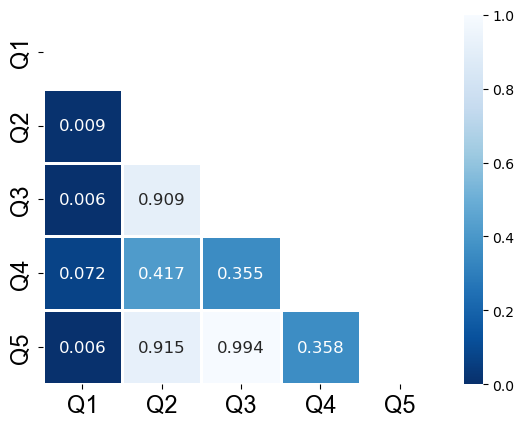

In [107]:
group1 = merge_House_value2[merge_House_value2['catogroy']=="Q1"]['mean_13_14']
group2 = merge_House_value2[merge_House_value2['catogroy']=="Q2"]['mean_13_14']
group3 = merge_House_value2[merge_House_value2['catogroy']=="Q3"]['mean_13_14']
group4 = merge_House_value2[merge_House_value2['catogroy']=="Q4"]['mean_13_14']
group5 = merge_House_value2[merge_House_value2['catogroy']=="Q5"]['mean_13_14']
data = [group1,group2,group3,group4,group5]

test_df = sp.posthoc_dunn(data)
table = test_df.rename(columns={1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4', 5: 'Q5'}, index={1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4', 5: 'Q5'})
mask = np.triu(np.ones_like(table))

dataplot = sns.heatmap(table, cmap='Blues_r', linewidths=1, annot=True, annot_kws={'size': 12}, fmt=".3f", mask=mask, vmin=0, vmax=1) #, , center=0.05, cbar=False
plt.xticks(fontsize=17,fontname = "Arial")
plt.yticks(fontsize=17,fontname = "Arial")
plt.savefig(figure_dir / "housevalue_initialhit.png",dpi=300)
plt.show()

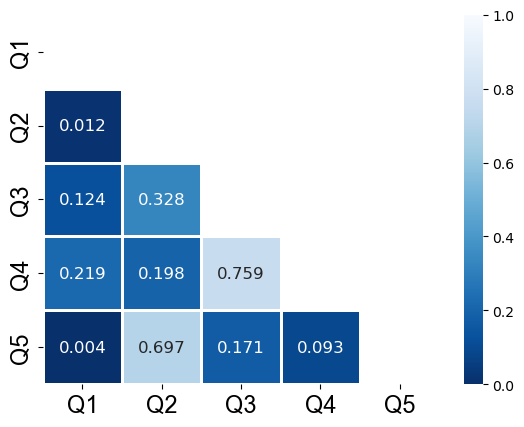

In [108]:
group1 = merge_House_value2[merge_House_value2['catogroy']=="Q1"]['ntl1']
group2 = merge_House_value2[merge_House_value2['catogroy']=="Q2"]['ntl1']
group3 = merge_House_value2[merge_House_value2['catogroy']=="Q3"]['ntl1']
group4 = merge_House_value2[merge_House_value2['catogroy']=="Q4"]['ntl1']
group5 = merge_House_value2[merge_House_value2['catogroy']=="Q5"]['ntl1']
data = [group1,group2,group3,group4,group5]

test_df = sp.posthoc_dunn(data)
table = test_df.rename(columns={1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4', 5: 'Q5'}, index={1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4', 5: 'Q5'})
mask = np.triu(np.ones_like(table))

dataplot = sns.heatmap(table, cmap='Blues_r', linewidths=1, annot=True, annot_kws={'size': 12}, fmt=".3f", mask=mask, vmin=0, vmax=1) #, , center=0.05, cbar=False
plt.xticks(fontsize=17,fontname = "Arial")
plt.yticks(fontsize=17,fontname = "Arial")
plt.savefig(figure_dir / "housevalue_poweroutage.png",dpi=300)
plt.show()

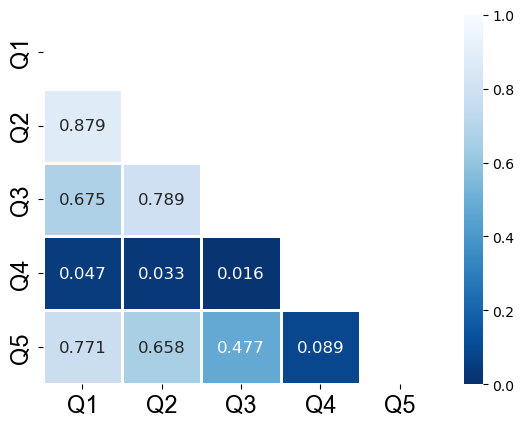

In [117]:
group1 = merge_House_value2[merge_House_value2['catogroy']=="Q1"]['mean_19_28']
group2 = merge_House_value2[merge_House_value2['catogroy']=="Q2"]['mean_19_28']
group3 = merge_House_value2[merge_House_value2['catogroy']=="Q3"]['mean_19_28']
group4 = merge_House_value2[merge_House_value2['catogroy']=="Q4"]['mean_19_28']
group5 = merge_House_value2[merge_House_value2['catogroy']=="Q5"]['mean_19_28']
data = [group1,group2,group3,group4,group5]

test_df = sp.posthoc_dunn(data) # 
table = test_df.rename(columns={1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4', 5: 'Q5'}, index={1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4', 5: 'Q5'})
mask = np.triu(np.ones_like(table))

dataplot = sns.heatmap(table, cmap='Blues_r', linewidths=1, annot=True, annot_kws={'size': 12}, fmt=".3f", mask=mask, vmin=0, vmax=1) #, , center=0.05, cbar=False
plt.xticks(fontsize=17,fontname = "Arial")
plt.yticks(fontsize=17,fontname = "Arial")
plt.savefig(figure_dir / "housevalue_recovery.png",dpi=300)
plt.show()

### Non-Hispanic and non-Black population

In [90]:
merge_non_minority1 = pd.merge(minority, hdt, left_on='GEOID', right_on='census_tract', how='left')
merge_non_minority2 = pd.merge(merge_non_minority1, ntl, left_on='GEOID', right_on='GEOID', how='left')
merge_non_minority2['ntl1'] = (-merge_non_minority2['ntl']) * 100
merge_non_minority2.head()

,GEOID,min_rank,catogroy,census_tract,mean_13_14,mean_15_18,mean_19_28,ntl,ntl1
0,48201100000,0.742638,Q4,48201100000,23.249437,21.757653,-12.321885,-0.251687,25.168702
1,48201210400,0.216389,Q2,48201210400,38.512239,20.350594,5.827102,0.219782,-21.978191
2,48201210500,0.112676,Q1,48201210500,9.819623,43.643126,4.142784,-0.098852,9.885152
3,48201210600,0.354673,Q2,48201210600,7.412045,12.924301,18.390544,-0.578316,57.831642
4,48201210700,0.113956,Q1,48201210700,28.489654,37.531816,-4.864677,0.637659,-63.765865


In [91]:
merge_non_minority_nlt_207 = pd.merge(minority, ntl_207, left_on='GEOID', right_on='GEOID', how='left')
merge_non_minority_nlt_216 = pd.merge(minority, ntl_216, left_on='GEOID', right_on='GEOID', how='left')

In [121]:
print(stats.kruskal(merge_non_minority2[merge_non_minority2['catogroy']=='Q1']['mean_13_14'], merge_non_minority2[merge_non_minority2['catogroy']=='Q2']['mean_13_14'], merge_non_minority2[merge_non_minority2['catogroy']=='Q3']['mean_13_14'], merge_non_minority2[merge_non_minority2['catogroy']=='Q4']['mean_13_14'], merge_non_minority2[merge_non_minority2['catogroy']=='Q5']['mean_13_14']))
print(stats.kruskal(merge_non_minority2[merge_non_minority2['catogroy']=='Q1']['ntl'], merge_non_minority2[merge_non_minority2['catogroy']=='Q2']['ntl'], merge_non_minority2[merge_non_minority2['catogroy']=='Q3']['ntl'], merge_non_minority2[merge_non_minority2['catogroy']=='Q4']['ntl'], merge_non_minority2[merge_non_minority2['catogroy']=='Q5']['ntl']))
print(stats.kruskal(merge_non_minority2[merge_non_minority2['catogroy']=='Q1']['mean_19_28'], merge_non_minority2[merge_non_minority2['catogroy']=='Q2']['mean_19_28'], merge_non_minority2[merge_non_minority2['catogroy']=='Q3']['mean_19_28'], merge_non_minority2[merge_non_minority2['catogroy']=='Q4']['mean_19_28'], merge_non_minority2[merge_non_minority2['catogroy']=='Q5']['mean_19_28']))

KruskalResult(statistic=19.763268902885557, pvalue=0.0005561024622991992)
KruskalResult(statistic=4.526481607914775, pvalue=0.33941898502095036)
KruskalResult(statistic=2.970240340786404, pvalue=0.5628178973443724)


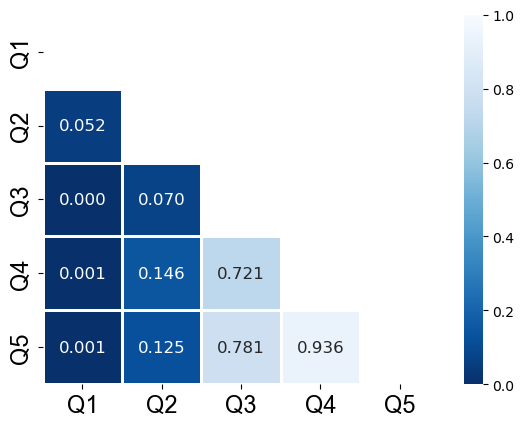

In [110]:
group1 = merge_non_minority2[merge_non_minority2['catogroy']=="Q1"]['mean_13_14']
group2 = merge_non_minority2[merge_non_minority2['catogroy']=="Q2"]['mean_13_14']
group3 = merge_non_minority2[merge_non_minority2['catogroy']=="Q3"]['mean_13_14']
group4 = merge_non_minority2[merge_non_minority2['catogroy']=="Q4"]['mean_13_14']
group5 = merge_non_minority2[merge_non_minority2['catogroy']=="Q5"]['mean_13_14']
data = [group1,group2,group3,group4,group5]

test_df = sp.posthoc_dunn(data)
table = test_df.rename(columns={1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4', 5: 'Q5'}, index={1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4', 5: 'Q5'})
mask = np.triu(np.ones_like(table))

dataplot = sns.heatmap(table, cmap='Blues_r', linewidths=1, annot=True, annot_kws={'size': 12}, fmt=".3f", mask=mask, vmin=0, vmax=1) #, , center=0.05, cbar=False
plt.xticks(fontsize=17,fontname = "Arial")
plt.yticks(fontsize=17,fontname = "Arial")
plt.savefig(figure_dir / "nonminority_initialhit.png",dpi=300)
plt.show()

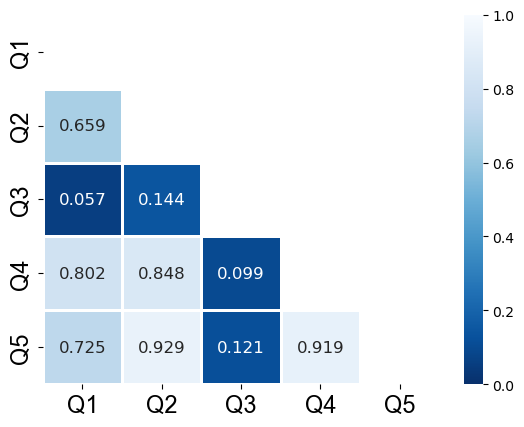

In [111]:
group1 = merge_non_minority2[merge_non_minority2['catogroy']=="Q1"]['ntl1']
group2 = merge_non_minority2[merge_non_minority2['catogroy']=="Q2"]['ntl1']
group3 = merge_non_minority2[merge_non_minority2['catogroy']=="Q3"]['ntl1']
group4 = merge_non_minority2[merge_non_minority2['catogroy']=="Q4"]['ntl1']
group5 = merge_non_minority2[merge_non_minority2['catogroy']=="Q5"]['ntl1']
data = [group1,group2,group3,group4,group5]

test_df = sp.posthoc_dunn(data)
table = test_df.rename(columns={1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4', 5: 'Q5'}, index={1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4', 5: 'Q5'})
mask = np.triu(np.ones_like(table))

dataplot = sns.heatmap(table, cmap='Blues_r', linewidths=1, annot=True, annot_kws={'size': 12}, fmt=".3f", mask=mask, vmin=0, vmax=1) #, , center=0.05, cbar=False
plt.xticks(fontsize=17,fontname = "Arial")
plt.yticks(fontsize=17,fontname = "Arial")
plt.savefig(figure_dir / "nonminority_poweroutage.png",dpi=300)
plt.show()

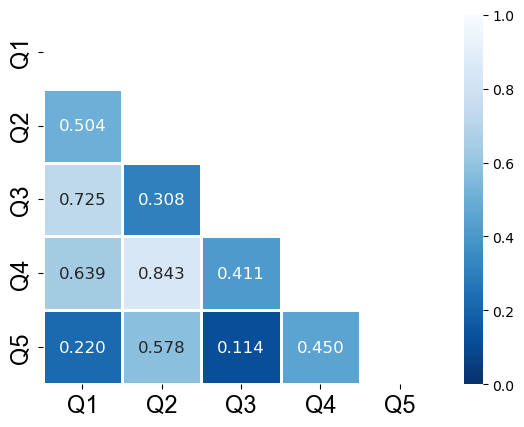

In [112]:
group1 = merge_non_minority2[merge_non_minority2['catogroy']=="Q1"]['mean_19_28']
group2 = merge_non_minority2[merge_non_minority2['catogroy']=="Q2"]['mean_19_28']
group3 = merge_non_minority2[merge_non_minority2['catogroy']=="Q3"]['mean_19_28']
group4 = merge_non_minority2[merge_non_minority2['catogroy']=="Q4"]['mean_19_28']
group5 = merge_non_minority2[merge_non_minority2['catogroy']=="Q5"]['mean_19_28']
data = [group1,group2,group3,group4,group5]

test_df = sp.posthoc_dunn(data)
table = test_df.rename(columns={1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4', 5: 'Q5'}, index={1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4', 5: 'Q5'})
mask = np.triu(np.ones_like(table))

dataplot = sns.heatmap(table, cmap='Blues_r', linewidths=1, annot=True, annot_kws={'size': 12}, fmt=".3f", mask=mask, vmin=0, vmax=1) #, , center=0.05, cbar=False
plt.xticks(fontsize=17,fontname = "Arial")
plt.yticks(fontsize=17,fontname = "Arial")
plt.savefig(figure_dir / "nonminority_recovery.png",dpi=300)
plt.show()

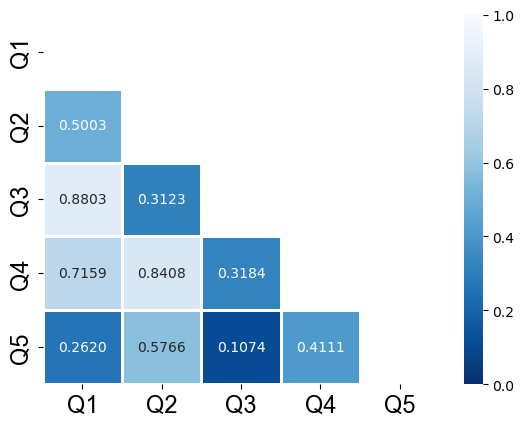

In [38]:
lis_big = []
for m in ["Q1","Q2","Q3","Q4","Q5"]:
    lis = []
    for i in ["Q1","Q2","Q3","Q4","Q5"]:
        pvalue = ranksums(merge_non_minority2[merge_non_minority2['catogroy']==m]['mean_19_28'], merge_non_minority2[merge_non_minority2['catogroy']==i]['mean_19_28']).pvalue
        pvalue1 = round(pvalue, 4)
        lis.append(pvalue1)
    lis_big.append(lis)

idx= ["Q1","Q2","Q3","Q4","Q5"]
cols = ["Q1","Q2","Q3","Q4","Q5"]
table = pd.DataFrame(lis_big, index=idx, columns=cols)
mask = np.triu(np.ones_like(table))

dataplot = sns.heatmap(table, cmap='Blues_r', linewidths=1, annot=True, fmt=".4f", mask=mask, vmin=0, vmax=1) #, , center=0.05, cbar=False
plt.xticks(fontsize=17,fontname = "Arial")
plt.yticks(fontsize=17,fontname = "Arial")
plt.savefig(figure_dir / "nonminority_recovery.png",dpi=300)
plt.show()

### Households having vehicles

In [96]:
merge_Vehicle1 = pd.merge(Vehicle, hdt, left_on='GEOID', right_on='census_tract', how='left')
merge_Vehicle2 = pd.merge(merge_Vehicle1, ntl, left_on='GEOID', right_on='GEOID', how='left')
merge_Vehicle2['ntl1'] = (-merge_Vehicle2['ntl']) * 100
merge_Vehicle2.head()

,GEOID,vehicle_rank,catogroy,census_tract,mean_13_14,mean_15_18,mean_19_28,ntl,ntl1
0,48201100000,0.102433,Q1,48201100000,23.249437,21.757653,-12.321885,-0.251687,25.168702
1,48201210400,0.032010,Q1,48201210400,38.512239,20.350594,5.827102,0.219782,-21.978191
2,48201210500,0.133163,Q1,48201210500,9.819623,43.643126,4.142784,-0.098852,9.885152
3,48201210600,0.286812,Q2,48201210600,7.412045,12.924301,18.390544,-0.578316,57.831642
4,48201210700,0.539052,Q3,48201210700,28.489654,37.531816,-4.864677,0.637659,-63.765865


In [97]:
merge_Vehicle_nlt_207 = pd.merge(Vehicle, ntl_207, left_on='GEOID', right_on='GEOID', how='left')
merge_Vehicle_nlt_216 = pd.merge(Vehicle, ntl_216, left_on='GEOID', right_on='GEOID', how='left')

In [134]:
print(stats.kruskal(merge_Vehicle2[merge_Vehicle2['catogroy']=='Q1']['mean_13_14'], merge_Vehicle2[merge_Vehicle2['catogroy']=='Q2']['mean_13_14'], merge_Vehicle2[merge_Vehicle2['catogroy']=='Q3']['mean_13_14'], merge_Vehicle2[merge_Vehicle2['catogroy']=='Q4']['mean_13_14'], merge_Vehicle2[merge_Vehicle2['catogroy']=='Q5']['mean_13_14']))
print(stats.kruskal(merge_Vehicle2[merge_Vehicle2['catogroy']=='Q1']['ntl'],merge_Vehicle2[merge_Vehicle2['catogroy']=='Q2']['ntl'], merge_Vehicle2[merge_Vehicle2['catogroy']=='Q3']['ntl'],  merge_Vehicle2[merge_Vehicle2['catogroy']=='Q4']['ntl'], merge_Vehicle2[merge_Vehicle2['catogroy']=='Q5']['ntl']))
print(stats.kruskal(merge_Vehicle2[merge_Vehicle2['catogroy']=='Q1']['mean_19_28'], merge_Vehicle2[merge_Vehicle2['catogroy']=='Q2']['mean_19_28'], merge_Vehicle2[merge_Vehicle2['catogroy']=='Q3']['mean_19_28'], merge_Vehicle2[merge_Vehicle2['catogroy']=='Q4']['mean_19_28'], merge_Vehicle2[merge_Vehicle2['catogroy']=='Q5']['mean_19_28']))

KruskalResult(statistic=17.834910774816763, pvalue=0.0013292252671371534)
KruskalResult(statistic=4.266702221899777, pvalue=0.37111323895583337)
KruskalResult(statistic=6.034500115874835, pvalue=0.19658655630161706)


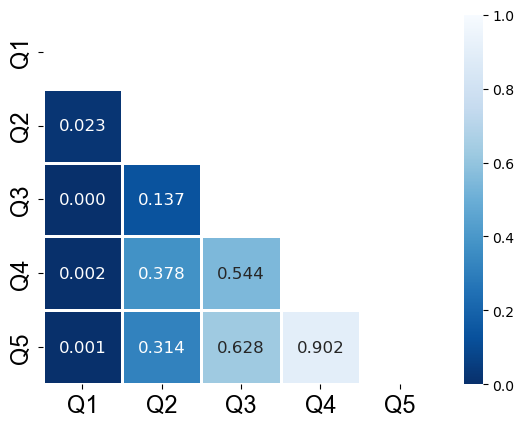

In [113]:
group1 = merge_Vehicle2[merge_Vehicle2['catogroy']=="Q1"]['mean_13_14']
group2 = merge_Vehicle2[merge_Vehicle2['catogroy']=="Q2"]['mean_13_14']
group3 = merge_Vehicle2[merge_Vehicle2['catogroy']=="Q3"]['mean_13_14']
group4 = merge_Vehicle2[merge_Vehicle2['catogroy']=="Q4"]['mean_13_14']
group5 = merge_Vehicle2[merge_Vehicle2['catogroy']=="Q5"]['mean_13_14']
data = [group1,group2,group3,group4,group5]

test_df = sp.posthoc_dunn(data)
table = test_df.rename(columns={1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4', 5: 'Q5'}, index={1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4', 5: 'Q5'})
mask = np.triu(np.ones_like(table))

dataplot = sns.heatmap(table, cmap='Blues_r', linewidths=1, annot=True, annot_kws={'size': 12}, fmt=".3f", mask=mask, vmin=0, vmax=1) #, , center=0.05, cbar=False
plt.xticks(fontsize=17,fontname = "Arial")
plt.yticks(fontsize=17,fontname = "Arial")
plt.savefig(figure_dir / "vehicle_initialhit.png",dpi=300)
plt.show()

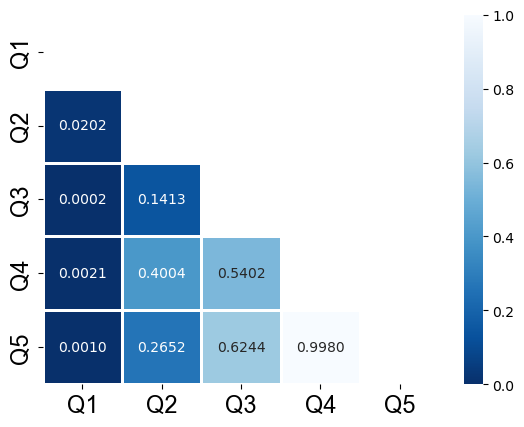

In [135]:
lis_big = []
for m in ["Q1","Q2","Q3","Q4","Q5"]:
    lis = []
    for i in ["Q1","Q2","Q3","Q4","Q5"]:
        pvalue = ranksums(merge_Vehicle2[merge_Vehicle2['catogroy']==m]['mean_13_14'], merge_Vehicle2[merge_Vehicle2['catogroy']==i]['mean_13_14']).pvalue
        pvalue1 = round(pvalue, 4)
        lis.append(pvalue1)
    lis_big.append(lis)

idx= ["Q1","Q2","Q3","Q4","Q5"]
cols = ["Q1","Q2","Q3","Q4","Q5"]
table = pd.DataFrame(lis_big, index=idx, columns=cols)
mask = np.triu(np.ones_like(table))

dataplot = sns.heatmap(table, cmap='Blues_r', linewidths=1, annot=True, fmt=".4f", mask=mask, vmin=0, vmax=1) #, , center=0.05, cbar=False
plt.xticks(fontsize=17,fontname = "Arial")
plt.yticks(fontsize=17,fontname = "Arial")
plt.savefig(figure_dir / "vehicle_initialhit.png",dpi=300)
plt.show()

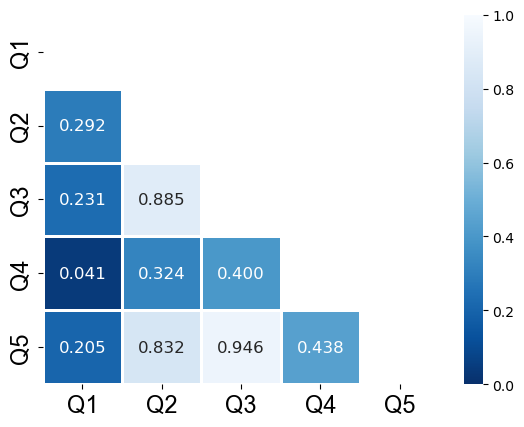

In [114]:
group1 = merge_Vehicle2[merge_Vehicle2['catogroy']=="Q1"]['ntl']
group2 = merge_Vehicle2[merge_Vehicle2['catogroy']=="Q2"]['ntl']
group3 = merge_Vehicle2[merge_Vehicle2['catogroy']=="Q3"]['ntl']
group4 = merge_Vehicle2[merge_Vehicle2['catogroy']=="Q4"]['ntl']
group5 = merge_Vehicle2[merge_Vehicle2['catogroy']=="Q5"]['ntl']
data = [group1,group2,group3,group4,group5]

test_df = sp.posthoc_dunn(data)
table = test_df.rename(columns={1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4', 5: 'Q5'}, index={1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4', 5: 'Q5'})
mask = np.triu(np.ones_like(table))

dataplot = sns.heatmap(table, cmap='Blues_r', linewidths=1, annot=True, annot_kws={'size': 12}, fmt=".3f", mask=mask, vmin=0, vmax=1) #, , center=0.05, cbar=False
plt.xticks(fontsize=17,fontname = "Arial")
plt.yticks(fontsize=17,fontname = "Arial")
plt.savefig(figure_dir / "vehicle_poweroutage.png",dpi=300)
plt.show()

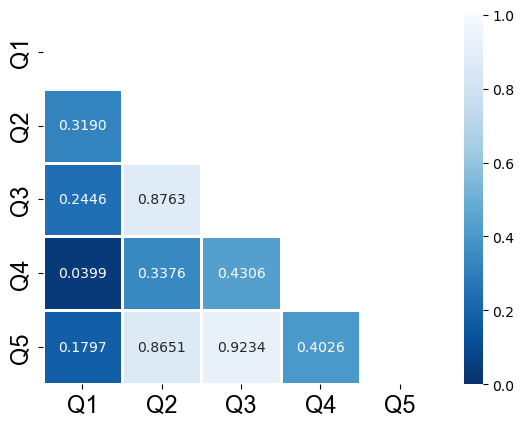

In [42]:
lis_big = []
for m in ["Q1","Q2","Q3","Q4","Q5"]:
    lis = []
    for i in ["Q1","Q2","Q3","Q4","Q5"]:
        pvalue = ranksums(merge_Vehicle2[merge_Vehicle2['catogroy']==m]['ntl'], merge_Vehicle2[merge_Vehicle2['catogroy']==i]['ntl']).pvalue
        pvalue1 = round(pvalue, 4)
        lis.append(pvalue1)
    lis_big.append(lis)

idx= ["Q1","Q2","Q3","Q4","Q5"]
cols = ["Q1","Q2","Q3","Q4","Q5"]
table = pd.DataFrame(lis_big, index=idx, columns=cols)
mask = np.triu(np.ones_like(table))

dataplot = sns.heatmap(table, cmap='Blues_r', linewidths=1, annot=True, fmt=".4f", mask=mask, vmin=0, vmax=1) #, , center=0.05, cbar=False
plt.xticks(fontsize=17,fontname = "Arial")
plt.yticks(fontsize=17,fontname = "Arial")
plt.savefig(figure_dir / "vehicle_poweroutage.png",dpi=300)
plt.show()

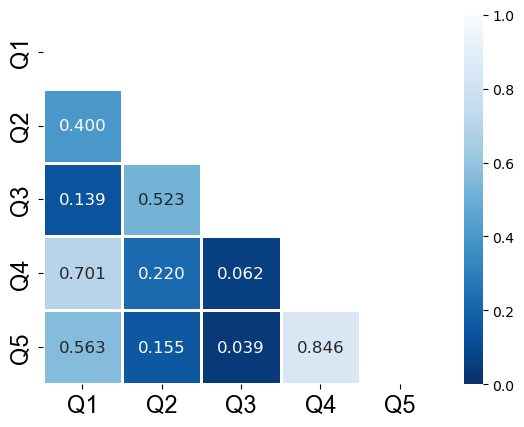

In [115]:
group1 = merge_Vehicle2[merge_Vehicle2['catogroy']=="Q1"]['mean_19_28']
group2 = merge_Vehicle2[merge_Vehicle2['catogroy']=="Q2"]['mean_19_28']
group3 = merge_Vehicle2[merge_Vehicle2['catogroy']=="Q3"]['mean_19_28']
group4 = merge_Vehicle2[merge_Vehicle2['catogroy']=="Q4"]['mean_19_28']
group5 = merge_Vehicle2[merge_Vehicle2['catogroy']=="Q5"]['mean_19_28']
data = [group1,group2,group3,group4,group5]

test_df = sp.posthoc_dunn(data)
table = test_df.rename(columns={1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4', 5: 'Q5'}, index={1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4', 5: 'Q5'})
mask = np.triu(np.ones_like(table))

dataplot = sns.heatmap(table, cmap='Blues_r', linewidths=1, annot=True, annot_kws={'size': 12}, fmt=".3f", mask=mask, vmin=0, vmax=1) #, , center=0.05, cbar=False
plt.xticks(fontsize=17,fontname = "Arial")
plt.yticks(fontsize=17,fontname = "Arial")
plt.savefig(figure_dir / "vehicle_recovery.png",dpi=300)
plt.show()

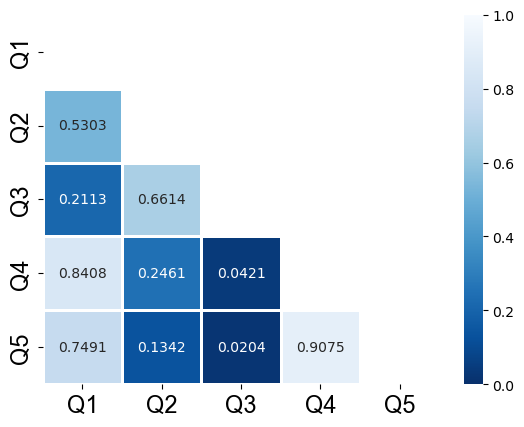

In [43]:
lis_big = []
for m in ["Q1","Q2","Q3","Q4","Q5"]:
    lis = []
    for i in ["Q1","Q2","Q3","Q4","Q5"]:
        pvalue = ranksums(merge_Vehicle2[merge_Vehicle2['catogroy']==m]['mean_19_28'], merge_Vehicle2[merge_Vehicle2['catogroy']==i]['mean_19_28']).pvalue
        pvalue1 = round(pvalue, 4)
        lis.append(pvalue1)
    lis_big.append(lis)

idx= ["Q1","Q2","Q3","Q4","Q5"]
cols = ["Q1","Q2","Q3","Q4","Q5"]
table = pd.DataFrame(lis_big, index=idx, columns=cols)
mask = np.triu(np.ones_like(table))

dataplot = sns.heatmap(table, cmap='Blues_r', linewidths=1, annot=True, fmt=".4f", mask=mask, vmin=0, vmax=1) #, , center=0.05, cbar=False
plt.xticks(fontsize=17,fontname = "Arial")
plt.yticks(fontsize=17,fontname = "Arial")
plt.savefig(figure_dir / "vehicle_recovery.png",dpi=300)
plt.show()

## Compare each quintile with the remaining tracts

### Median household income

In [28]:
print(stats.kruskal(merge_income2[merge_income2['catogroy']=='Q1']['mean_13_14'], merge_income2[merge_income2['catogroy']!='Q1']['mean_13_14']))
print(stats.kruskal(merge_income2[merge_income2['catogroy']=='Q2']['mean_13_14'], merge_income2[merge_income2['catogroy']!='Q2']['mean_13_14']))
print(stats.kruskal(merge_income2[merge_income2['catogroy']=='Q3']['mean_13_14'], merge_income2[merge_income2['catogroy']!='Q3']['mean_13_14']))
print(stats.kruskal(merge_income2[merge_income2['catogroy']=='Q4']['mean_13_14'], merge_income2[merge_income2['catogroy']!='Q4']['mean_13_14']))
print(stats.kruskal(merge_income2[merge_income2['catogroy']=='Q5']['mean_13_14'], merge_income2[merge_income2['catogroy']!='Q5']['mean_13_14']))

KruskalResult(statistic=10.918314538658251, pvalue=0.0009521819963929462)
KruskalResult(statistic=0.6627116269919497, pvalue=0.4156042661357223)
KruskalResult(statistic=1.950092465079706, pvalue=0.16257688708236542)
KruskalResult(statistic=3.7542326972256888, pvalue=0.052673966441582024)
KruskalResult(statistic=0.6122144691121321, pvalue=0.433955239671594)


In [46]:
print(stats.kruskal(merge_income2[merge_income2['catogroy']=='Q1']['ntl1'], merge_income2[merge_income2['catogroy']!='Q1']['ntl1']))
print(stats.kruskal(merge_income2[merge_income2['catogroy']=='Q2']['ntl1'], merge_income2[merge_income2['catogroy']!='Q2']['ntl1']))
print(stats.kruskal(merge_income2[merge_income2['catogroy']=='Q3']['ntl1'], merge_income2[merge_income2['catogroy']!='Q3']['ntl1']))
print(stats.kruskal(merge_income2[merge_income2['catogroy']=='Q4']['ntl1'], merge_income2[merge_income2['catogroy']!='Q4']['ntl1']))
print(stats.kruskal(merge_income2[merge_income2['catogroy']=='Q5']['ntl1'], merge_income2[merge_income2['catogroy']!='Q5']['ntl1']))

KruskalResult(statistic=0.22777241786343438, pvalue=0.6331804888276911)
KruskalResult(statistic=1.3401100137712092, pvalue=0.24701456799786287)
KruskalResult(statistic=5.445276254180499, pvalue=0.01962131171956776)
KruskalResult(statistic=0.7890019279952867, pvalue=0.37440209125034174)
KruskalResult(statistic=4.496718172602414, pvalue=0.03395997025046701)


In [30]:
print(stats.kruskal(merge_income2[merge_income2['catogroy']=='Q1']['mean_19_28'], merge_income2[merge_income2['catogroy']!='Q1']['mean_19_28']))
print(stats.kruskal(merge_income2[merge_income2['catogroy']=='Q2']['mean_19_28'], merge_income2[merge_income2['catogroy']!='Q2']['mean_19_28']))
print(stats.kruskal(merge_income2[merge_income2['catogroy']=='Q3']['mean_19_28'], merge_income2[merge_income2['catogroy']!='Q3']['mean_19_28']))
print(stats.kruskal(merge_income2[merge_income2['catogroy']=='Q4']['mean_19_28'], merge_income2[merge_income2['catogroy']!='Q4']['mean_19_28']))
print(stats.kruskal(merge_income2[merge_income2['catogroy']=='Q5']['mean_19_28'], merge_income2[merge_income2['catogroy']!='Q5']['mean_19_28']))

KruskalResult(statistic=0.323644461931508, pvalue=0.5694256445433794)
KruskalResult(statistic=1.4881959472750168, pvalue=0.22249657989303256)
KruskalResult(statistic=0.8275190241984092, pvalue=0.36299091144187035)
KruskalResult(statistic=0.4516444619316644, pvalue=0.5015550583986774)
KruskalResult(statistic=4.961333582279167, pvalue=0.025920210345256423)


### Non-Hispanic and non-Black population

In [31]:
print(stats.kruskal(merge_non_minority2[merge_non_minority2['catogroy']=='Q1']['mean_13_14'], merge_non_minority2[merge_non_minority2['catogroy']!='Q1']['mean_13_14']))
print(stats.kruskal(merge_non_minority2[merge_non_minority2['catogroy']=='Q2']['mean_13_14'], merge_non_minority2[merge_non_minority2['catogroy']!='Q2']['mean_13_14']))
print(stats.kruskal(merge_non_minority2[merge_non_minority2['catogroy']=='Q3']['mean_13_14'], merge_non_minority2[merge_non_minority2['catogroy']!='Q3']['mean_13_14']))
print(stats.kruskal(merge_non_minority2[merge_non_minority2['catogroy']=='Q4']['mean_13_14'], merge_non_minority2[merge_non_minority2['catogroy']!='Q4']['mean_13_14']))
print(stats.kruskal(merge_non_minority2[merge_non_minority2['catogroy']=='Q5']['mean_13_14'], merge_non_minority2[merge_non_minority2['catogroy']!='Q5']['mean_13_14']))

KruskalResult(statistic=15.78914121581738, pvalue=7.080772795870753e-05)
KruskalResult(statistic=0.81744497344107, pvalue=0.3659282561432967)
KruskalResult(statistic=3.8299412158171435, pvalue=0.050344698412578125)
KruskalResult(statistic=1.9368190438717647, pvalue=0.1640143339752249)
KruskalResult(statistic=2.3265568630795315, pvalue=0.12718291701952825)


In [32]:
print(stats.kruskal(merge_non_minority2[merge_non_minority2['catogroy']=='Q1']['ntl1'], merge_non_minority2[merge_non_minority2['catogroy']!='Q1']['ntl1']))
print(stats.kruskal(merge_non_minority2[merge_non_minority2['catogroy']=='Q2']['ntl1'], merge_non_minority2[merge_non_minority2['catogroy']!='Q2']['ntl1']))
print(stats.kruskal(merge_non_minority2[merge_non_minority2['catogroy']=='Q3']['ntl1'], merge_non_minority2[merge_non_minority2['catogroy']!='Q3']['ntl1']))
print(stats.kruskal(merge_non_minority2[merge_non_minority2['catogroy']=='Q4']['ntl1'], merge_non_minority2[merge_non_minority2['catogroy']!='Q4']['ntl1']))
print(stats.kruskal(merge_non_minority2[merge_non_minority2['catogroy']=='Q5']['ntl1'], merge_non_minority2[merge_non_minority2['catogroy']!='Q5']['ntl1']))

KruskalResult(statistic=0.866215384615316, pvalue=0.3520051853358033)
KruskalResult(statistic=0.0542308085773584, pvalue=0.815858400278979)
KruskalResult(statistic=4.308294156993725, pvalue=0.03792697480430765)
KruskalResult(statistic=0.2864136927009895, pvalue=0.5925279396941613)
KruskalResult(statistic=0.14136355605205608, pvalue=0.7069291984773934)


In [33]:
print(stats.kruskal(merge_non_minority2[merge_non_minority2['catogroy']=='Q1']['mean_19_28'], merge_non_minority2[merge_non_minority2['catogroy']!='Q1']['mean_19_28']))
print(stats.kruskal(merge_non_minority2[merge_non_minority2['catogroy']=='Q2']['mean_19_28'], merge_non_minority2[merge_non_minority2['catogroy']!='Q2']['mean_19_28']))
print(stats.kruskal(merge_non_minority2[merge_non_minority2['catogroy']=='Q3']['mean_19_28'], merge_non_minority2[merge_non_minority2['catogroy']!='Q3']['mean_19_28']))
print(stats.kruskal(merge_non_minority2[merge_non_minority2['catogroy']=='Q4']['mean_19_28'], merge_non_minority2[merge_non_minority2['catogroy']!='Q4']['mean_19_28']))
print(stats.kruskal(merge_non_minority2[merge_non_minority2['catogroy']=='Q5']['mean_19_28'], merge_non_minority2[merge_non_minority2['catogroy']!='Q5']['mean_19_28']))

KruskalResult(statistic=0.40543379893779274, pvalue=0.52429627505531)
KruskalResult(statistic=0.17517607711988603, pvalue=0.6755520456757689)
KruskalResult(statistic=1.4249979933110808, pvalue=0.2325825064702914)
KruskalResult(statistic=0.011219988195989572, pvalue=0.9156422983161259)
KruskalResult(statistic=1.6975004730393266, pvalue=0.19261518539551598)


### Median house value

In [34]:
print(stats.kruskal(merge_House_value2[merge_House_value2['catogroy']=='Q1']['mean_13_14'], merge_House_value2[merge_House_value2['catogroy']!='Q1']['mean_13_14']))
print(stats.kruskal(merge_House_value2[merge_House_value2['catogroy']=='Q2']['mean_13_14'], merge_House_value2[merge_House_value2['catogroy']!='Q2']['mean_13_14']))
print(stats.kruskal(merge_House_value2[merge_House_value2['catogroy']=='Q3']['mean_13_14'], merge_House_value2[merge_House_value2['catogroy']!='Q3']['mean_13_14']))
print(stats.kruskal(merge_House_value2[merge_House_value2['catogroy']=='Q4']['mean_13_14'], merge_House_value2[merge_House_value2['catogroy']!='Q4']['mean_13_14']))
print(stats.kruskal(merge_House_value2[merge_House_value2['catogroy']=='Q5']['mean_13_14'], merge_House_value2[merge_House_value2['catogroy']!='Q5']['mean_13_14']))

KruskalResult(statistic=9.720854770804635, pvalue=0.001821887640289785)
KruskalResult(statistic=1.0226088530394009, pvalue=0.31190098020250656)
KruskalResult(statistic=1.419320716112452, pvalue=0.23351524221718495)
KruskalResult(statistic=0.0740658666145464, pvalue=0.785506340593645)
KruskalResult(statistic=1.4031486558792494, pvalue=0.23619709367016356)


In [35]:
print(stats.kruskal(merge_House_value2[merge_House_value2['catogroy']=='Q1']['ntl1'], merge_House_value2[merge_House_value2['catogroy']!='Q1']['ntl1']))
print(stats.kruskal(merge_House_value2[merge_House_value2['catogroy']=='Q2']['ntl1'], merge_House_value2[merge_House_value2['catogroy']!='Q2']['ntl1']))
print(stats.kruskal(merge_House_value2[merge_House_value2['catogroy']=='Q3']['ntl1'], merge_House_value2[merge_House_value2['catogroy']!='Q3']['ntl1']))
print(stats.kruskal(merge_House_value2[merge_House_value2['catogroy']=='Q4']['ntl1'], merge_House_value2[merge_House_value2['catogroy']!='Q4']['ntl1']))
print(stats.kruskal(merge_House_value2[merge_House_value2['catogroy']=='Q5']['ntl1'], merge_House_value2[merge_House_value2['catogroy']!='Q5']['ntl1']))

KruskalResult(statistic=6.7193635254770925, pvalue=0.009537165660022388)
KruskalResult(statistic=1.9213906747982037, pvalue=0.1657034342453206)
KruskalResult(statistic=0.025943104465568467, pvalue=0.8720393450551158)
KruskalResult(statistic=0.41867574267143937, pvalue=0.5175985635762037)
KruskalResult(statistic=4.037426021044212, pvalue=0.044501648053621924)


In [36]:
print(stats.kruskal(merge_House_value2[merge_House_value2['catogroy']=='Q1']['mean_19_28'], merge_House_value2[merge_House_value2['catogroy']!='Q1']['mean_19_28']))
print(stats.kruskal(merge_House_value2[merge_House_value2['catogroy']=='Q2']['mean_19_28'], merge_House_value2[merge_House_value2['catogroy']!='Q2']['mean_19_28']))
print(stats.kruskal(merge_House_value2[merge_House_value2['catogroy']=='Q3']['mean_19_28'], merge_House_value2[merge_House_value2['catogroy']!='Q3']['mean_19_28']))
print(stats.kruskal(merge_House_value2[merge_House_value2['catogroy']=='Q4']['mean_19_28'], merge_House_value2[merge_House_value2['catogroy']!='Q4']['mean_19_28']))
print(stats.kruskal(merge_House_value2[merge_House_value2['catogroy']=='Q5']['mean_19_28'], merge_House_value2[merge_House_value2['catogroy']!='Q5']['mean_19_28']))

KruskalResult(statistic=0.29024812118814225, pvalue=0.5900615722645594)
KruskalResult(statistic=0.6070896714536502, pvalue=0.43588570926213743)
KruskalResult(statistic=1.4449577021441655, pvalue=0.2293387583119267)
KruskalResult(statistic=6.762624434389181, pvalue=0.009308675748623997)
KruskalResult(statistic=0.0064547931092420185, pvalue=0.9359654720494672)


### Households having vehicles

In [37]:
print(stats.kruskal(merge_Vehicle2[merge_Vehicle2['catogroy']=='Q1']['mean_13_14'],merge_Vehicle2[merge_Vehicle2['catogroy']!='Q1']['mean_13_14']))
print(stats.kruskal(merge_Vehicle2[merge_Vehicle2['catogroy']=='Q2']['mean_13_14'],merge_Vehicle2[merge_Vehicle2['catogroy']!='Q2']['mean_13_14']))
print(stats.kruskal(merge_Vehicle2[merge_Vehicle2['catogroy']=='Q3']['mean_13_14'],merge_Vehicle2[merge_Vehicle2['catogroy']!='Q3']['mean_13_14']))
print(stats.kruskal(merge_Vehicle2[merge_Vehicle2['catogroy']=='Q4']['mean_13_14'],merge_Vehicle2[merge_Vehicle2['catogroy']!='Q4']['mean_13_14']))
print(stats.kruskal(merge_Vehicle2[merge_Vehicle2['catogroy']=='Q5']['mean_13_14'],merge_Vehicle2[merge_Vehicle2['catogroy']!='Q5']['mean_13_14']))

KruskalResult(statistic=15.525417902812933, pvalue=8.140329004696386e-05)
KruskalResult(statistic=0.12299130434757899, pvalue=0.7258125544379033)
KruskalResult(statistic=4.0074154633089165, pvalue=0.045300543000730484)
KruskalResult(statistic=1.0878049970488064, pvalue=0.29695806273181924)
KruskalResult(statistic=1.5453473925199432, pvalue=0.21382360820808918)


In [38]:
print(stats.kruskal(merge_Vehicle2[merge_Vehicle2['catogroy']=='Q1']['ntl'],merge_Vehicle2[merge_Vehicle2['catogroy']!='Q1']['ntl']))
print(stats.kruskal(merge_Vehicle2[merge_Vehicle2['catogroy']=='Q2']['ntl'],merge_Vehicle2[merge_Vehicle2['catogroy']!='Q2']['ntl']))
print(stats.kruskal(merge_Vehicle2[merge_Vehicle2['catogroy']=='Q3']['ntl'],merge_Vehicle2[merge_Vehicle2['catogroy']!='Q3']['ntl']))
print(stats.kruskal(merge_Vehicle2[merge_Vehicle2['catogroy']=='Q4']['ntl'],merge_Vehicle2[merge_Vehicle2['catogroy']!='Q4']['ntl']))
print(stats.kruskal(merge_Vehicle2[merge_Vehicle2['catogroy']=='Q5']['ntl'],merge_Vehicle2[merge_Vehicle2['catogroy']!='Q5']['ntl']))

KruskalResult(statistic=3.0915009246509726, pvalue=0.07870218265300755)
KruskalResult(statistic=0.008325791855440912, pvalue=0.9272973016971917)
KruskalResult(statistic=0.0188417863464565, pvalue=0.8908210289438604)
KruskalResult(statistic=2.153468581546349, pvalue=0.1422482091584688)
KruskalResult(statistic=0.059629419157772645, pvalue=0.8070826200892245)


In [39]:
print(stats.kruskal(merge_Vehicle2[merge_Vehicle2['catogroy']=='Q1']['mean_19_28'],merge_Vehicle2[merge_Vehicle2['catogroy']!='Q1']['mean_19_28']))
print(stats.kruskal(merge_Vehicle2[merge_Vehicle2['catogroy']=='Q2']['mean_19_28'],merge_Vehicle2[merge_Vehicle2['catogroy']!='Q2']['mean_19_28']))
print(stats.kruskal(merge_Vehicle2[merge_Vehicle2['catogroy']=='Q3']['mean_19_28'],merge_Vehicle2[merge_Vehicle2['catogroy']!='Q3']['mean_19_28']))
print(stats.kruskal(merge_Vehicle2[merge_Vehicle2['catogroy']=='Q4']['mean_19_28'],merge_Vehicle2[merge_Vehicle2['catogroy']!='Q4']['mean_19_28']))
print(stats.kruskal(merge_Vehicle2[merge_Vehicle2['catogroy']=='Q5']['mean_19_28'],merge_Vehicle2[merge_Vehicle2['catogroy']!='Q5']['mean_19_28']))

KruskalResult(statistic=0.1835766279755262, pvalue=0.6683173909700745)
KruskalResult(statistic=0.8138620499703393, pvalue=0.36698089232895625)
KruskalResult(statistic=3.658003698602897, pvalue=0.05580045400655386)
KruskalResult(statistic=1.072138500885103, pvalue=0.30046290826305133)
KruskalResult(statistic=1.8160361251630093, pvalue=0.17778583299916684)


## Selected quintile medians

In [124]:
import statistics
print(statistics.median(merge_income2[merge_income2['catogroy']=='Q4']['mean_13_14']))
print(statistics.median(merge_non_minority2[merge_non_minority2['catogroy']=='Q3']['mean_13_14']))
print(statistics.median(merge_House_value2[merge_House_value2['catogroy']=='Q3']['mean_13_14']))
print(statistics.median(merge_Vehicle2[merge_House_value2['catogroy']=='Q3']['mean_13_14']))

8.1123925145
7.6864710115
8.264261681
8.264261681


In [48]:
print(statistics.median(merge_income2[merge_income2['catogroy']=='Q5']['ntl1']))
print(statistics.median(merge_income2[merge_income2['catogroy']=='Q3']['ntl1']))
print(statistics.median(merge_House_value2[merge_House_value2['catogroy']=='Q5']['ntl1']))
print(statistics.median(merge_House_value2[merge_House_value2['catogroy']=='Q1']['ntl1']))

12.93455769621826
-2.55178631407592
12.196404360049561
-14.25857907193705


In [49]:
print(statistics.median(merge_non_minority2[merge_non_minority2['catogroy']=='Q3']['ntl1']))

-12.02050854970086


In [51]:
print(statistics.median(merge_income2[merge_income2['catogroy']=='Q5']['mean_19_28']))

1.953537138


In [52]:
print(statistics.median(merge_House_value2[merge_House_value2['catogroy']=='Q4']['mean_19_28']))

1.9426924209999998


## Box plots

### Initial-hit stage (February 13–14)

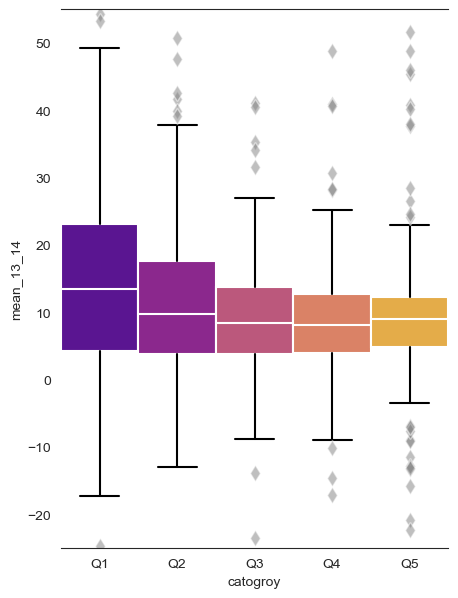

In [40]:
plt.figure(figsize=(5,7))
sns.set_style("white")
PROPS = {
    'boxprops':{'edgecolor':'white'},
    'medianprops':{'color':'white'},
    'whiskerprops':{'color':'black'},
    'capprops':{'color':'black'}
}
sns.boxplot(x="catogroy",
            y="mean_13_14",
            data=merge_income2,
            order=['Q1','Q2','Q3','Q4','Q5'],
            palette="plasma", #plasma
            width=1,
            flierprops = dict(markerfacecolor = '0.5', markersize = 7.7, alpha = 0.5, markeredgecolor='white'),
            **PROPS
           )

sns.despine(left=True, bottom=False, right=True, top=False)

plt.ylim(-25,55)
plt.savefig(figure_dir / "mean_13_14_income.png", dpi=300)

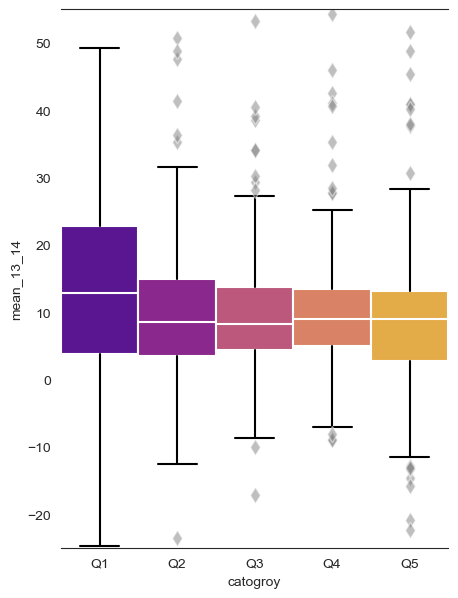

In [38]:
plt.figure(figsize=(5,7))
sns.set_style("white")
PROPS = {
    'boxprops':{'edgecolor':'white'},
    'medianprops':{'color':'white'},
    'whiskerprops':{'color':'black'},
    'capprops':{'color':'black'}
}
sns.boxplot(x="catogroy",
            y="mean_13_14",
            data=merge_House_value2,
            order=['Q1','Q2','Q3','Q4','Q5'],
            palette="plasma", #plasma
            width=1,
            flierprops = dict(markerfacecolor = '0.5', markersize = 7.7, alpha = 0.5, markeredgecolor='white'),
            **PROPS
           )

sns.despine(left=True, bottom=False, right=True, top=False)

plt.ylim(-25,55)
plt.savefig(figure_dir / "mean_13_14_house_value.png", dpi=300)

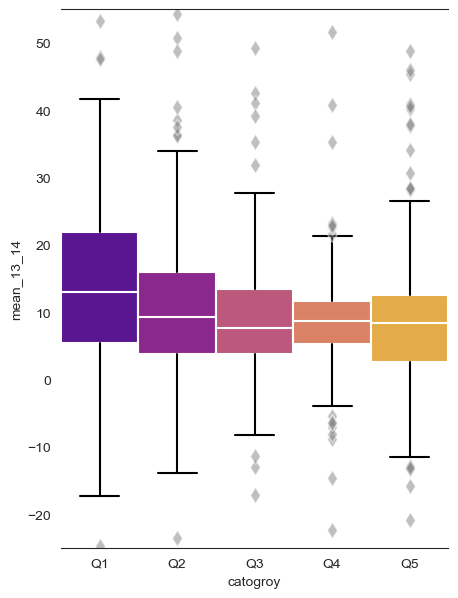

In [37]:
plt.figure(figsize=(5,7))
sns.set_style("white")
PROPS = {
    'boxprops':{'edgecolor':'white'},
    'medianprops':{'color':'white'}, 
    'whiskerprops':{'color':'black'},
    'capprops':{'color':'black'}
}
sns.boxplot(x="catogroy",
            y="mean_13_14",
            data=merge_non_minority2,
            order=['Q1','Q2','Q3','Q4','Q5'],
            palette="plasma", #plasma
            width=1,
            flierprops = dict(markerfacecolor = '0.5', markersize = 7.7, alpha = 0.5, markeredgecolor='white'),
            **PROPS
           )

sns.despine(left=True, bottom=False, right=True, top=False)

plt.ylim(-25,55)
plt.savefig(figure_dir / "mean_13_14_non_minority.png", dpi=300)

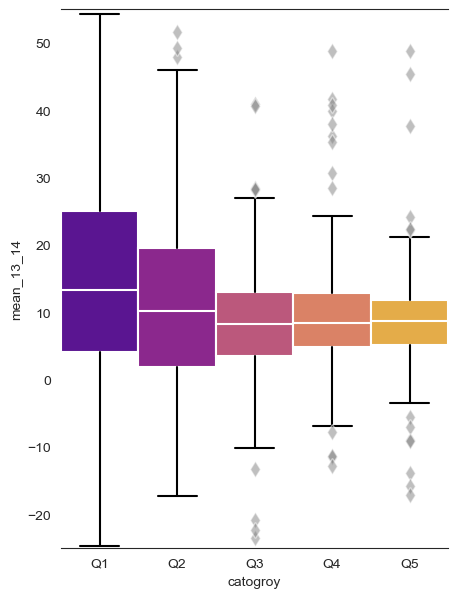

In [39]:
plt.figure(figsize=(5,7))
sns.set_style("white")
PROPS = {
    'boxprops':{'edgecolor':'white'},
    'medianprops':{'color':'white'},
    'whiskerprops':{'color':'black'},
    'capprops':{'color':'black'}
}
sns.boxplot(x="catogroy",
            y="mean_13_14",
            data=merge_Vehicle2,
            order=['Q1','Q2','Q3','Q4','Q5'],
            palette="plasma", #plasma
            width=1,
            flierprops = dict(markerfacecolor = '0.5', markersize = 7.7, alpha = 0.5, markeredgecolor='white'),
            **PROPS
           )

sns.despine(left=True, bottom=False, right=True, top=False)

plt.ylim(-25,55)
plt.savefig(figure_dir / "mean_13_14_non_vehicle.png", dpi=300)

### Power-outage stage (February 15–18)

(0.0, 2000.0)

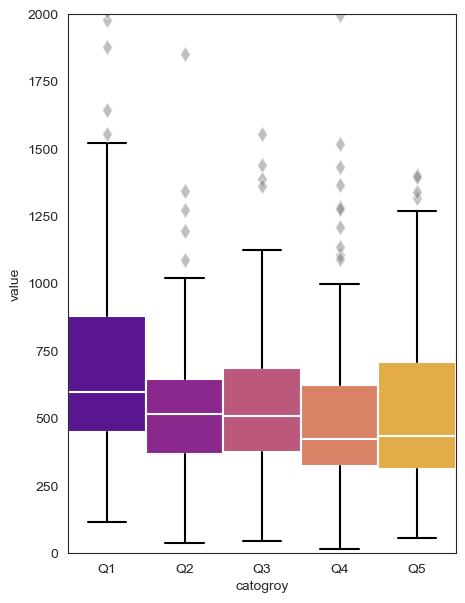

In [34]:
plt.figure(figsize=(5,7))
sns.set_style("white")
PROPS = {
    'boxprops':{'edgecolor':'white'},
    'medianprops':{'color':'white'},
    'whiskerprops':{'color':'black'},
    'capprops':{'color':'black'}
}
sns.boxplot(x="catogroy",
            y="value",
            data=merge_income_nlt_207,
            order=['Q1','Q2','Q3','Q4','Q5'],
            palette="plasma", #plasma
            width=1,
            flierprops = dict(markerfacecolor = '0.5', markersize = 7.7, alpha = 0.5, markeredgecolor='white'),
            **PROPS
           )

plt.ylim(0,2000)
#plt.savefig(figure_dir / "ntl_income.png", dpi=300)

(0.0, 2000.0)

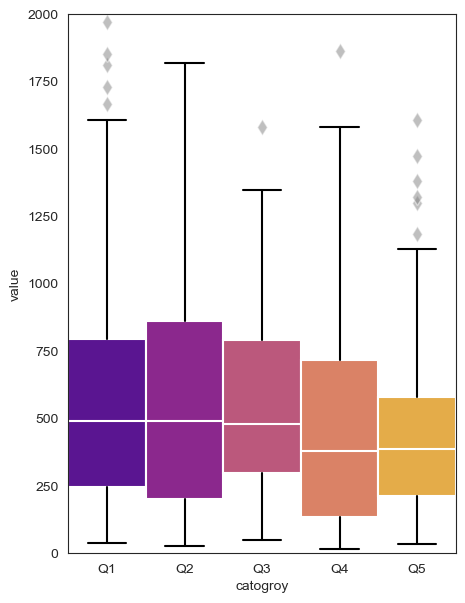

In [35]:
plt.figure(figsize=(5,7))
sns.set_style("white")
PROPS = {
    'boxprops':{'edgecolor':'white'},
    'medianprops':{'color':'white'},
    'whiskerprops':{'color':'black'},
    'capprops':{'color':'black'}
}
sns.boxplot(x="catogroy",
            y="value",
            data=merge_income_nlt_216,
            order=['Q1','Q2','Q3','Q4','Q5'],
            palette="plasma", #plasma
            width=1,
            flierprops = dict(markerfacecolor = '0.5', markersize = 7.7, alpha = 0.5, markeredgecolor='white'),
            **PROPS
           )
plt.ylim(0,2000)

<AxesSubplot:xlabel='catogroy', ylabel='nlt'>

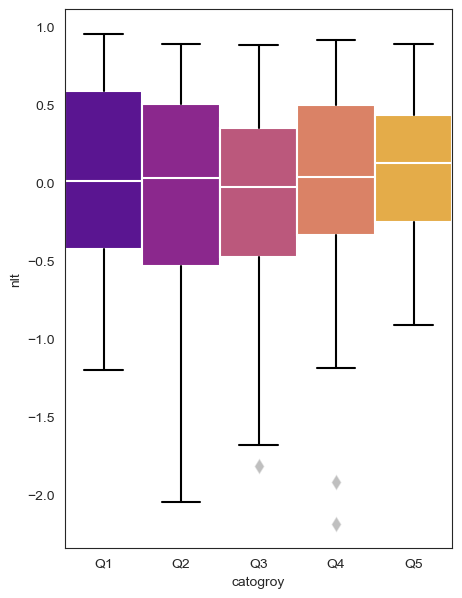

In [43]:
plt.figure(figsize=(5,7))
sns.set_style("white")
PROPS = {
    'boxprops':{'edgecolor':'white'},
    'medianprops':{'color':'white'},
    'whiskerprops':{'color':'black'},
    'capprops':{'color':'black'}
}
sns.boxplot(x="catogroy",
            y="nlt",
            data=merge_income_nlt_2,
            order=['Q1','Q2','Q3','Q4','Q5'],
            palette="plasma", #plasma
            width=1,
            flierprops = dict(markerfacecolor = '0.5', markersize = 7.7, alpha = 0.5, markeredgecolor='white'),
            **PROPS
           )

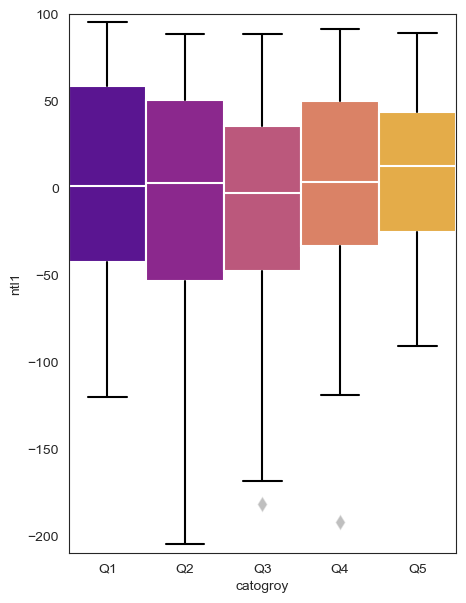

In [26]:
plt.figure(figsize=(5,7))
sns.set_style("white")
PROPS = {
    'boxprops':{'edgecolor':'white'},
    'medianprops':{'color':'white'},
    'whiskerprops':{'color':'black'},
    'capprops':{'color':'black'}
}
sns.boxplot(x="catogroy",
            y="ntl1",
            data=merge_income2,
            order=['Q1','Q2','Q3','Q4','Q5'],
            palette="plasma", #plasma
            width=1,
            flierprops = dict(markerfacecolor = '0.5', markersize = 7.7, alpha = 0.5, markeredgecolor='white'),
            **PROPS
           )

plt.ylim(-210,100)
plt.savefig(figure_dir / "ntl_income.png", dpi=300)

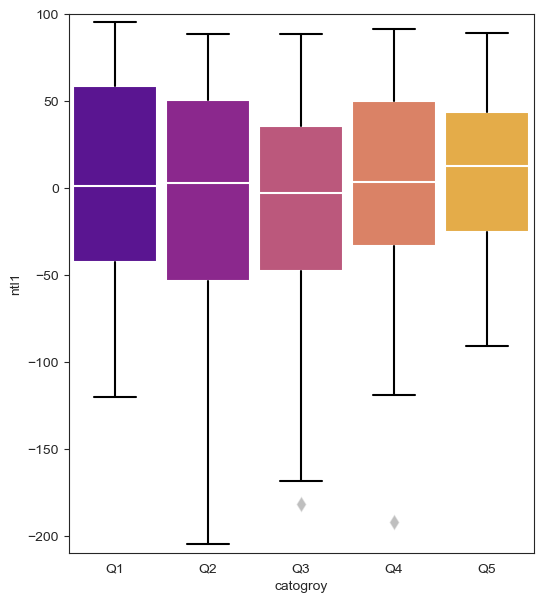

In [27]:
plt.figure(figsize=(6,7))
sns.set_style("white")
PROPS = {
    'boxprops':{'edgecolor':'white'},
    'medianprops':{'color':'white'},
    'whiskerprops':{'color':'black'},
    'capprops':{'color':'black'}
}
sns.boxplot(x="catogroy",
            y="ntl1",
            data=merge_income2,
            order=['Q1','Q2','Q3','Q4','Q5'],
            palette="plasma", #plasma
            width=0.9,
            flierprops = dict(markerfacecolor = '0.5', markersize = 7.7, alpha = 0.5, markeredgecolor='white'),
            **PROPS
           )

plt.tick_params(left=True)
plt.ylim(-210,100)
plt.savefig(figure_dir / "ntl_income1.png", dpi=300)

In [126]:
print(statistics.median(merge_non_minority2[merge_non_minority2['catogroy']=='Q1']['ntl1']))
print(statistics.median(merge_non_minority2[merge_non_minority2['catogroy']=='Q2']['ntl1']))
print(statistics.median(merge_non_minority2[merge_non_minority2['catogroy']=='Q3']['ntl1']))
print(statistics.median(merge_non_minority2[merge_non_minority2['catogroy']=='Q4']['ntl1']))
print(statistics.median(merge_non_minority2[merge_non_minority2['catogroy']=='Q5']['ntl1']))

7.764729125676865
8.65952314766445
-12.02050854970086
9.17138143262682
0.94216597220386


In [129]:
print(min(merge_non_minority2[merge_non_minority2['catogroy']=='Q1']['ntl1']))
print(min(merge_non_minority2[merge_non_minority2['catogroy']=='Q2']['ntl1']))
print(min(merge_non_minority2[merge_non_minority2['catogroy']=='Q3']['ntl1']))
print(min(merge_non_minority2[merge_non_minority2['catogroy']=='Q4']['ntl1']))
print(min(merge_non_minority2[merge_non_minority2['catogroy']=='Q5']['ntl1']))

-204.9023853097022
-142.7081688329759
-181.67097511568295
-218.6611660156009
-191.8083296052838


In [131]:
print(stats.kruskal(merge_non_minority2[merge_non_minority2['catogroy']=='Q1']['ntl1'], merge_non_minority2[merge_non_minority2['catogroy']=='Q2']['ntl1'], merge_non_minority2[merge_non_minority2['catogroy']=='Q3']['ntl1'], merge_non_minority2[merge_non_minority2['catogroy']=='Q4']['ntl1'], merge_non_minority2[merge_non_minority2['catogroy']=='Q5']['ntl1']))

KruskalResult(statistic=4.526481607914775, pvalue=0.33941898502095036)


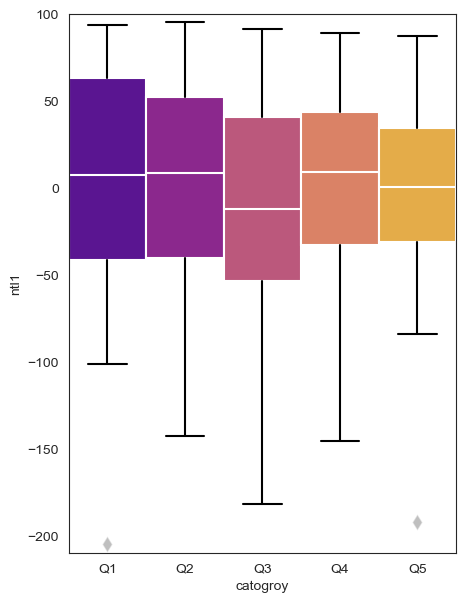

In [130]:
plt.figure(figsize=(5,7))
sns.set_style("white")
PROPS = {
    'boxprops':{'edgecolor':'white'},
    'medianprops':{'color':'white'},
    'whiskerprops':{'color':'black'},
    'capprops':{'color':'black'}
}
sns.boxplot(x="catogroy",
            y="ntl1",
            data=merge_non_minority2,
            order=['Q1','Q2','Q3','Q4','Q5'],
            palette="plasma", #plasma
            width=1,
            flierprops = dict(markerfacecolor = '0.5', markersize = 7.7, alpha = 0.5, markeredgecolor='white'),
            **PROPS
           )

plt.ylim(-210,100)
plt.savefig(figure_dir / "ntl_non_minority.png", dpi=300)

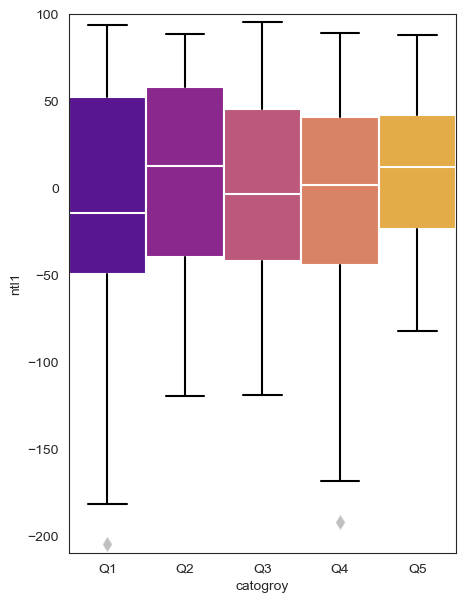

In [29]:
plt.figure(figsize=(5,7))
sns.set_style("white")
PROPS = {
    'boxprops':{'edgecolor':'white'},
    'medianprops':{'color':'white'},
    'whiskerprops':{'color':'black'},
    'capprops':{'color':'black'}
}
sns.boxplot(x="catogroy",
            y="ntl1",
            data=merge_House_value2,
            order=['Q1','Q2','Q3','Q4','Q5'],
            palette="plasma", #plasma
            width=1,
            flierprops = dict(markerfacecolor = '0.5', markersize = 7.7, alpha = 0.5, markeredgecolor='white'),
            **PROPS
           )

plt.ylim(-210,100)
plt.savefig(figure_dir / "ntl_house_value.png", dpi=300)

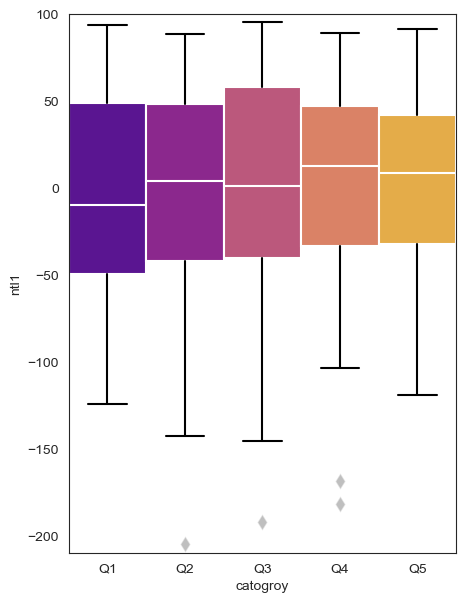

In [30]:
plt.figure(figsize=(5,7))
sns.set_style("white")
PROPS = {
    'boxprops':{'edgecolor':'white'},
    'medianprops':{'color':'white'},
    'whiskerprops':{'color':'black'},
    'capprops':{'color':'black'}
}
sns.boxplot(x="catogroy",
            y="ntl1",
            data=merge_Vehicle2,
            order=['Q1','Q2','Q3','Q4','Q5'],
            palette="plasma", #plasma
            width=1,
            flierprops = dict(markerfacecolor = '0.5', markersize = 7.7, alpha = 0.5, markeredgecolor='white'),
            **PROPS
           )

plt.ylim(-210,100)
plt.savefig(figure_dir / "ntl_merge_Vehicle.png", dpi=300)

### Recovery stage (February 19–28)

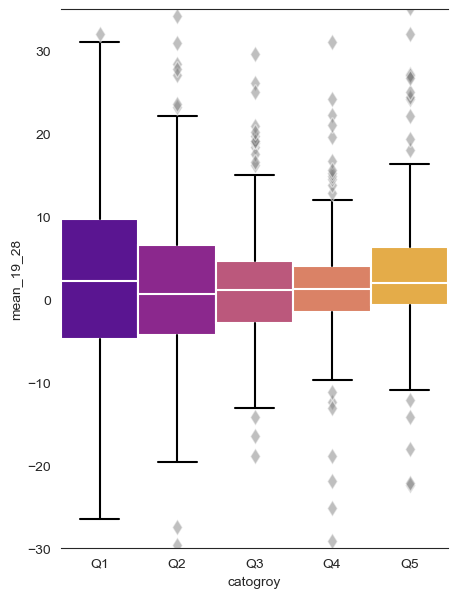

In [40]:
plt.figure(figsize=(5,7))
sns.set_style("white")
PROPS = {
    'boxprops':{'edgecolor':'white'},
    'medianprops':{'color':'white'},
    'whiskerprops':{'color':'black'},
    'capprops':{'color':'black'}
}
sns.boxplot(x="catogroy",
            y="mean_19_28",
            data=merge_income2,
            order=['Q1','Q2','Q3','Q4','Q5'],
            palette="plasma", #plasma
            width=1,
            flierprops = dict(markerfacecolor = '0.5', markersize = 7.7, alpha = 0.5, markeredgecolor='white'),
            **PROPS
           )

sns.despine(left=True, bottom=False, right=True, top=False)

plt.ylim(-30,35)
plt.savefig(figure_dir / "19_28_income.png", dpi=300)

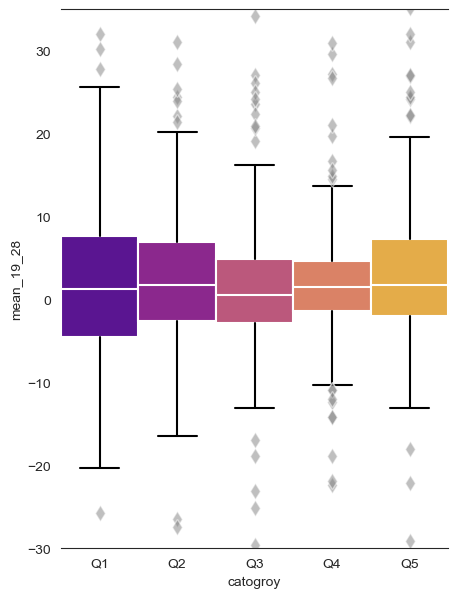

In [41]:
plt.figure(figsize=(5,7))
sns.set_style("white")
PROPS = {
    'boxprops':{'edgecolor':'white'},
    'medianprops':{'color':'white'},
    'whiskerprops':{'color':'black'},
    'capprops':{'color':'black'}
}
sns.boxplot(x="catogroy",
            y="mean_19_28",
            data=merge_non_minority2,
            order=['Q1','Q2','Q3','Q4','Q5'],
            palette="plasma", #plasma
            width=1,
            flierprops = dict(markerfacecolor = '0.5', markersize = 7.7, alpha = 0.5, markeredgecolor='white'),
            **PROPS
           )

sns.despine(left=True, bottom=False, right=True, top=False)

plt.ylim(-30,35)
plt.savefig(figure_dir / "19_28_non_minority.png", dpi=300)

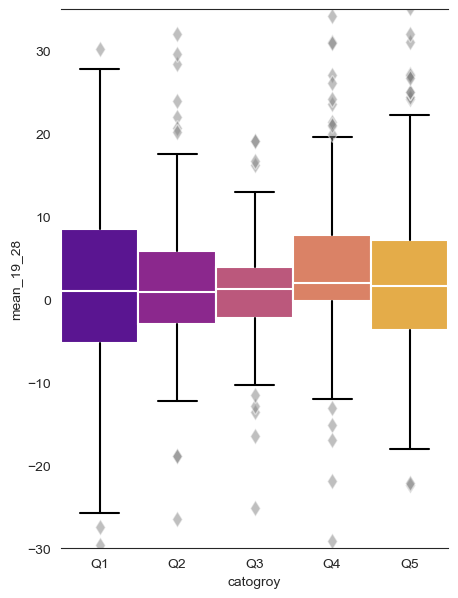

In [42]:
plt.figure(figsize=(5,7))
sns.set_style("white")
PROPS = {
    'boxprops':{'edgecolor':'white'},
    'medianprops':{'color':'white'},
    'whiskerprops':{'color':'black'},
    'capprops':{'color':'black'}
}
sns.boxplot(x="catogroy",
            y="mean_19_28",
            data=merge_House_value2,
            order=['Q1','Q2','Q3','Q4','Q5'],
            palette="plasma", #plasma
            width=1,
            flierprops = dict(markerfacecolor = '0.5', markersize = 7.7, alpha = 0.5, markeredgecolor='white'),
            **PROPS
           )

sns.despine(left=True, bottom=False, right=True, top=False)

plt.ylim(-30,35)
plt.savefig(figure_dir / "19_28_house_value.png", dpi=300)

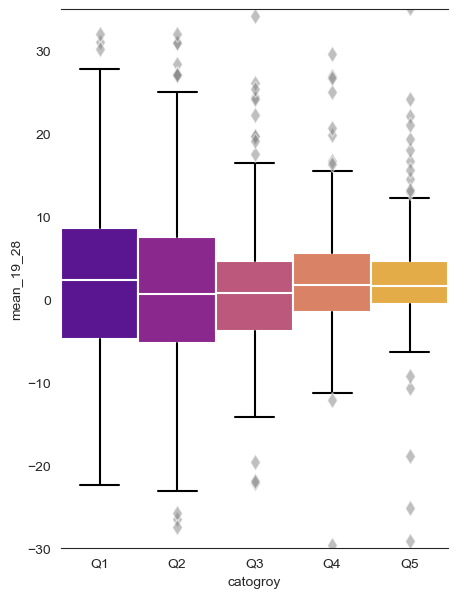

In [43]:
plt.figure(figsize=(5,7))
sns.set_style("white")
PROPS = {
    'boxprops':{'edgecolor':'white'},
    'medianprops':{'color':'white'},
    'whiskerprops':{'color':'black'},
    'capprops':{'color':'black'}
}
sns.boxplot(x="catogroy",
            y="mean_19_28",
            data=merge_Vehicle2,
            order=['Q1','Q2','Q3','Q4','Q5'],
            palette="plasma", #plasma
            width=1,
            flierprops = dict(markerfacecolor = '0.5', markersize = 7.7, alpha = 0.5, markeredgecolor='white'),
            **PROPS
           )

sns.despine(left=True, bottom=False, right=True, top=False)

plt.ylim(-30,35)
plt.savefig(figure_dir / "19_28_vehicle.png", dpi=300)